# 1. CƠ SỞ LÝ THUYẾT (SOFTMAX REGRESSION)

### 1.1. Công thức Softmax
Hàm Softmax nhận đầu vào là một vector các điểm số chưa chuẩn hóa (logits) $Z = [z_0, z_1, ..., z_{K-1}]$ cho $K$ lớp và chuyển đổi chúng thành một phân phối xác suất hợp lệ (các giá trị nằm trong khoảng $[0, 1]$ và có tổng bằng $1$):

$$\hat{y}_i = P(y = i | x) = \frac{e^{z_i}}{\sum_{j=0}^{K-1} e^{z_j}}$$

* **Ý nghĩa:** Biến đổi các điểm số dự đoán thô thành xác suất thuộc vào mỗi lớp, giúp ta dễ dàng đưa ra quyết định dự đoán lớp có xác suất cao nhất.
* **Ổn định số học (Numerical Stability):** Trong thực tế tính toán, để tránh hiện tượng tràn số (overflow) khi số mũ lớn, ta hiệu chỉnh bằng cách trừ đi giá trị lớn nhất:
  $$\text{Softmax}(z_i) = \frac{e^{z_i - \max(Z)}}{\sum e^{z_j - \max(Z)}}$$

### 1.2. Hàm hao hụt Cross-Entropy Loss
Để đo lường độ sai lệch giữa phân phối xác suất dự đoán $\hat{Y}$ và nhãn thực tế $Y$ (dưới dạng One-Hot vector), chúng ta sử dụng hàm hao hụt Cross-Entropy:

$$\mathcal{L}(Y, \hat{Y}) = -\frac{1}{N} \sum_{n=1}^{N} \sum_{k=0}^{K-1} y_{n, k} \ln(\hat{y}_{n, k})$$

* **Ý nghĩa:** Phạt rất nặng các dự đoán tự tin nhưng sai lệch lớn so với nhãn gốc (khi $y_{n,k} = 1$ nhưng $\hat{y}_{n,k} \to 0$ thì $-\ln(\hat{y}_{n,k}) \to \infty$). Việc cực tiểu hóa hàm này tương đương với tối đa hóa xác suất đồng thời (Maximum Likelihood Estimation) của mô hình phân loại.

### 1.3. Công thức Gradient của Ma trận Trọng số
Gradient của hàm hao hụt đối với ma trận trọng số $W$ (đã gộp cả bias sau khi thêm cột $1$ vào đầu vector dữ liệu đầu vào $X$) được tính theo công thức:

$$\nabla_{W} \mathcal{L} = \frac{1}{N} X^T (\hat{Y} - Y)$$

* **Ý nghĩa:** Cho biết hướng thay đổi của trọng số để hàm hao hụt tăng nhanh nhất. Để giảm hao hụt, chúng ta cần đi ngược hướng gradient này.

### 1.4. Thuật toán tối ưu Gradient Descent
Để cập nhật trọng số và tìm cực tiểu của hàm hao hụt, ta cập nhật ma trận trọng số theo công thức lặp:

$$W^{(t+1)} = W^{(t)} - \eta \cdot \nabla_{W} \mathcal{L}$$

* **Ý nghĩa:** $\eta$ (Learning Rate) là hệ số học tập kiểm soát kích thước bước đi mỗi lần cập nhật. Gradient Descent dịch chuyển ma trận trọng số từng bước nhỏ xuống dốc của bề mặt hao hụt cho đến khi hội tụ.

### 1.5. Lý do lựa chọn Softmax Regression cho bài toán nhận diện 10 chữ số
1. **Phân loại đa lớp tuyến tính:** MNIST có 10 lớp ($0 \to 9$) rời rạc, không có thứ tự mang tính định lượng. Softmax Regression là mô hình phân loại đa lớp chuẩn hóa tự nhiên nhất từ Logistic Regression nhị phân.
2. **Tốc độ và hiệu năng:** Mô hình không chứa các lớp ẩn phi tuyến phức tạp giúp huấn luyện cực kỳ nhanh, tiêu tốn ít tài nguyên tính toán nhưng vẫn đem lại độ chính xác nền tảng rất tốt (~88-92%) để làm mốc đối chứng (baseline) trước khi thử nghiệm các mô hình phức tạp hơn như MLP hay CNN.

# 2. QUÁ TRÌNH HUẤN LUYỆN

### 2.1. Giải thích các bước thực hiện huấn luyện
Quá trình huấn luyện mô hình Softmax Regression sử dụng thuật toán Gradient Descent bao gồm các bước lặp đi lặp lại sau:
1. **Khởi tạo tham số**: Ma trận trọng số $W$ được khởi tạo ngẫu nhiên với các giá trị nhỏ gần bằng 0 để tránh hiện tượng bão hòa sớm.
2. **Lan truyền xuôi (Forward Propagation)**: Tính điểm số logits $Z = X \cdot W$, sau đó áp dụng hàm kích hoạt `Softmax` để chuyển đổi logits thành xác suất dự đoán $\hat{Y}$.
3. **Tính toán Loss**: Đo lường sai số giữa xác suất dự đoán $\hat{Y}$ và nhãn thực tế $Y$ (dạng One-hot) bằng hàm Cross-Entropy Loss trên toàn bộ tập huấn luyện.
4. **Lan truyền ngược & Tính Gradient (Backward Propagation)**: Tính toán đạo hàm riêng của Loss đối với trọng số $\nabla_{W} \mathcal{L} = \frac{1}{N} X^T (\hat{Y} - Y)$.
5. **Cập nhật trọng số (Gradient Descent)**: Điều chỉnh $W$ ngược hướng với Gradient với tốc độ học $\eta$: $W \leftarrow W - \eta \cdot \nabla_{W} \mathcal{L}$.
6. **Đánh giá định kỳ**: Sau mỗi epoch, tính toán hao hụt trên tập Validation để theo dõi tiến trình hội tụ và phát hiện sớm hiện tượng quá khớp (Overfitting).

In [ ]:
# CELL 6: KIỂM TRA ĐẦU VÀO CỦA MÔ HÌNH

# Đảm bảo các biến được lấy từ môi trường hiện tại hoặc sử dụng giá trị mô hình đã huấn luyện
W_eval = globals().get('W_model', globals().get('W', None))
d_eval = globals().get('d', 784)
X_eval_train = globals().get('X', None)
X_eval_val = globals().get('X_val', None)

if W_eval is not None and X_eval_train is not None:
    print("Số đặc trưng của mô hình:", d_eval)
    print("Số trọng số:", W_eval.shape)
    print("Kích thước đầu vào Training:", X_eval_train.shape)
    print("Kích thước đầu vào Validation:", X_eval_val.shape)

    assert X_eval_train.shape[1] == 785
    assert X_eval_val.shape[1] == 785
    assert W_eval.shape == (785, 10)
    print("Các tập dữ liệu có cùng định dạng đầu vào!")
else:
    print("Vui lòng chạy các ô chuẩn bị dữ liệu và huấn luyện mô hình phía dưới trước!")

Vui lòng chạy các ô chuẩn bị dữ liệu và huấn luyện mô hình phía dưới trước!


In [ ]:
# CELL 6: KIỂM TRA ĐẦU VÀO CỦA MÔ HÌNH (DỰ PHÒNG)

W_eval = globals().get('W_model', globals().get('W', None))
d_eval = globals().get('d', 784)
X_eval_train = globals().get('X', None)
X_eval_val = globals().get('X_val', None)

if W_eval is not None and X_eval_train is not None:
    print("Số đặc trưng của mô hình:", d_eval)
    print("Số trọng số:", W_eval.shape)
    print("Kích thước đầu vào Training:", X_eval_train.shape)
    print("Kích thước đầu vào Validation:", X_eval_val.shape)

    assert X_eval_train.shape[1] == 785
    assert X_eval_val.shape[1] == 785
    assert W_eval.shape == (785, 10)
    print("Các tập dữ liệu có cùng định dạng đầu vào!")
else:
    print("Vui lòng chạy các ô chuẩn bị dữ liệu và huấn luyện mô hình phía dưới trước!")

Vui lòng chạy các ô chuẩn bị dữ liệu và huấn luyện mô hình phía dưới trước!


## 1. Dữ liệu, tiền xử lý, chia tập dữ liệu

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# CELL 1: TẢI, CHIA TẬP VÀ TIỀN XỬ LÝ MNIST
# ==========================================

# 1. Tải bộ dữ liệu MNIST chuẩn (từ TensorFlow Keras hoặc file mnist.npz dự phòng)
try:
    from tensorflow.keras.datasets import mnist
    (X_all, y_all), (X_test_raw, y_test) = mnist.load_data()
    print("Nguồn dữ liệu: MNIST - tensorflow.keras.datasets")
except Exception:
    import os
    mnist_path = 'mnist.npz' if os.path.exists('mnist.npz') else os.path.join(r'd:\Học máy', 'mnist.npz')
    with np.load(mnist_path) as f:
        X_all, y_all = f['x_train'], f['y_train']
        X_test_raw, y_test = f['x_test'], f['y_test']
    print(f"Nguồn dữ liệu: MNIST - file '{mnist_path}'")

print("Training ban đầu:", X_all.shape, y_all.shape)
print("Testing chính thức:", X_test_raw.shape, y_test.shape)

# 2. Chia 60.000 ảnh train thành Training (55.000) và Validation (5.000)
np.random.seed(0)
indices = np.random.permutation(len(X_all))
train_indices = indices[:55000]
val_indices = indices[55000:]

# Giữ bản ảnh gốc 28x28 để kiểm tra và trực quan hóa
train_images_raw = X_all[train_indices].copy()
train_labels = y_all[train_indices].copy()
val_images_raw = X_all[val_indices].copy()
val_labels = y_all[val_indices].copy()
test_images_raw = X_test_raw.copy()

print("\nSau khi chia tập:")
print("Training:", train_images_raw.shape, train_labels.shape)
print("Validation:", val_images_raw.shape, val_labels.shape)
print("Testing:", test_images_raw.shape, y_test.shape)

# 3. Kiểm tra dữ liệu gốc
assert len(train_images_raw) == len(train_labels)
assert len(val_images_raw) == len(val_labels)
assert len(test_images_raw) == len(y_test)
assert train_images_raw.shape[1:] == (28, 28)
assert val_images_raw.shape[1:] == (28, 28)
assert test_images_raw.shape[1:] == (28, 28)
assert np.all(np.isin(train_labels, np.arange(10)))
assert np.all(np.isin(val_labels, np.arange(10)))
assert np.all(np.isin(y_test, np.arange(10)))
assert np.all(np.isfinite(train_images_raw))
assert np.all(np.isfinite(val_images_raw))
assert np.all(np.isfinite(test_images_raw))
print("\nKiểm tra dữ liệu gốc: hợp lệ!")

# 4. Tiền xử lý ảnh MNIST: uint8 [0,255] -> float32 [0,1]
train_images = train_images_raw.astype(np.float32) / 255.0
val_images = val_images_raw.astype(np.float32) / 255.0
test_images = test_images_raw.astype(np.float32) / 255.0

# 5. Làm phẳng ảnh 28x28 thành vector 784 chiều
train_images = train_images.reshape(len(train_images), 784)
val_images = val_images.reshape(len(val_images), 784)
test_images = test_images.reshape(len(test_images), 784)

# Các biến train_images, val_images, test_images là dữ liệu đã chuẩn hóa,
# mỗi hàng là một ảnh 784 chiều. Nhãn vẫn ở dạng số nguyên 0-9.
N = train_images.shape[0]
d = train_images.shape[1]

print("\nKết quả sau tiền xử lý:")
print("Training:", train_images.shape, train_labels.shape)
print("Validation:", val_images.shape, val_labels.shape)
print("Testing:", test_images.shape, y_test.shape)
print("Số đặc trưng mỗi ảnh:", d)
print("Miền giá trị pixel:", float(train_images.min()), "đến", float(train_images.max()))


Nguồn dữ liệu: MNIST - file 'mnist.npz'
Training ban đầu: (60000, 28, 28) (60000,)
Testing chính thức: (10000, 28, 28) (10000,)

Sau khi chia tập:
Training: (55000, 28, 28) (55000,)
Validation: (5000, 28, 28) (5000,)
Testing: (10000, 28, 28) (10000,)

Kiểm tra dữ liệu gốc: hợp lệ!

Kết quả sau tiền xử lý:
Training: (55000, 784) (55000,)
Validation: (5000, 784) (5000,)
Testing: (10000, 784) (10000,)
Số đặc trưng mỗi ảnh: 784
Miền giá trị pixel: 0.0 đến 1.0


Kích thước ảnh Training gốc: (55000, 28, 28)
Kích thước ảnh Validation gốc: (5000, 28, 28)
Kích thước ảnh Testing gốc: (10000, 28, 28)
Các nhãn: [0 1 2 3 4 5 6 7 8 9]
Giá trị pixel gốc: 0 đến 255
Giá trị pixel sau chuẩn hóa: 0.0 đến 1.0


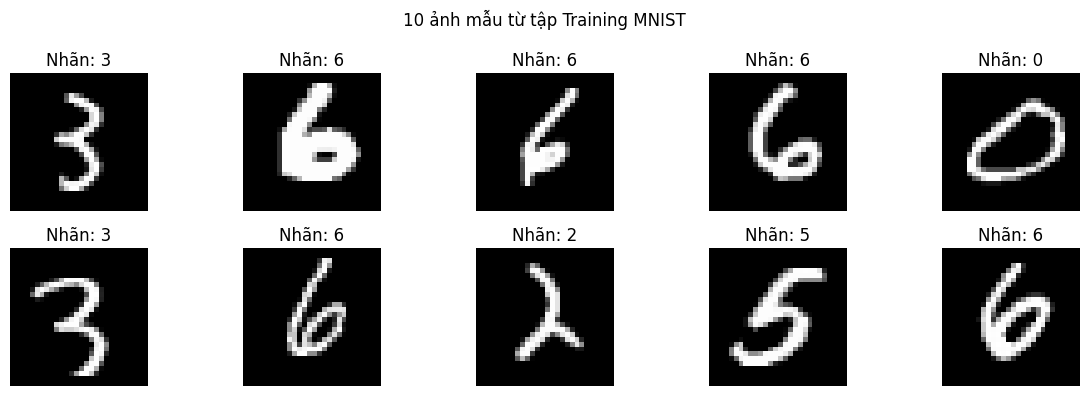

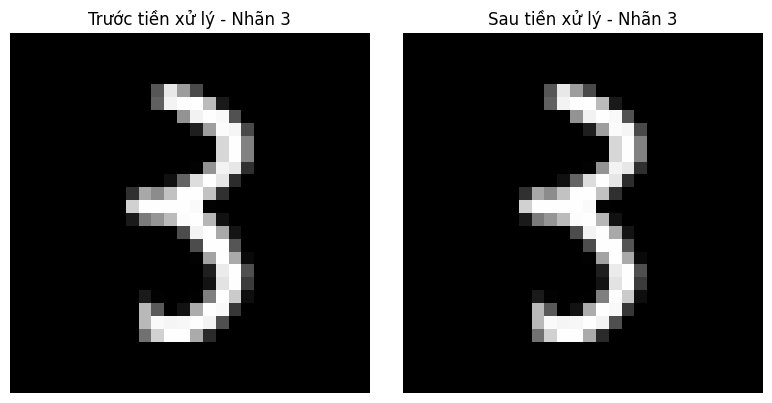

In [ ]:
# CELL 2: MÔ TẢ VÀ HIỂN THỊ MẪU DỮ LIỆU MNIST

print("Kích thước ảnh Training gốc:", train_images_raw.shape)
print("Kích thước ảnh Validation gốc:", val_images_raw.shape)
print("Kích thước ảnh Testing gốc:", test_images_raw.shape)
print("Các nhãn:", np.unique(train_labels))
print("Giá trị pixel gốc:", train_images_raw.min(), "đến", train_images_raw.max())
print("Giá trị pixel sau chuẩn hóa:", train_images.min(), "đến", train_images.max())

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_images_raw[i], cmap="gray", vmin=0, vmax=255)
    plt.title(f"Nhãn: {train_labels[i]}")
    plt.axis("off")
plt.suptitle("10 ảnh mẫu từ tập Training MNIST")
plt.tight_layout()
plt.show()
# So sánh ảnh trước và sau tiền xử lý
index = 0

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(train_images_raw[index], cmap="gray", vmin=0, vmax=255)
plt.title(f"Trước tiền xử lý - Nhãn {train_labels[index]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(train_images[index].reshape(28, 28),
           cmap="gray", vmin=0, vmax=1)
plt.title(f"Sau tiền xử lý - Nhãn {train_labels[index]}")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# CELL 3: KIỂM TRA DỮ LIỆU ĐẦU VÀO

def check_dataset(images, labels, dataset_name):
    print(f"\n--- Kiểm tra {dataset_name} ---")
    if images is None or labels is None:
        print("Lỗi: Thiếu ảnh hoặc nhãn!")
        return False
    if len(images) == 0 or len(labels) == 0:
        print("Lỗi: Dữ liệu rỗng!")
        return False
    if len(images) != len(labels):
        print("Lỗi: Số ảnh và số nhãn không bằng nhau!")
        return False
    if images.ndim != 3 or images.shape[1:] != (28, 28):
        print("Lỗi: Ảnh phải có dạng (N, 28, 28)!")
        return False
    if not np.all(np.isfinite(images)):
        print("Lỗi: Ảnh chứa NaN hoặc Inf!")
        return False
    if not np.all(np.isin(labels, np.arange(10))):
        print("Lỗi: Nhãn phải thuộc các số từ 0 đến 9!")
        return False
    print("Dữ liệu hợp lệ!")
    return True

check_dataset(train_images_raw, train_labels, "Training")
check_dataset(val_images_raw, val_labels, "Validation")
check_dataset(test_images_raw, y_test, "Testing")



--- Kiểm tra Training ---
Dữ liệu hợp lệ!

--- Kiểm tra Validation ---
Dữ liệu hợp lệ!

--- Kiểm tra Testing ---
Dữ liệu hợp lệ!


### Mô hình Hồi quy Logistic đa lớp (Multiclass Logistic Regression) với Softmax và Gradient Descent

Phần dưới đây định nghĩa cấu trúc mô hình cơ bản bao gồm:
- Hàm kích hoạt **Softmax** đưa đầu ra về phân phối xác suất.
- Hàm tính độ hao hụt **Cross-Entropy Loss (Compute Cost)**.
- Thuật toán tối ưu **Gradient Descent** cập nhật trọng số liên tục.

In [ ]:
import numpy as np

# Khôi phục dữ liệu nếu bị reset
if 'X' not in globals() or 'Y' not in globals():
    try:
        from tensorflow.keras.datasets import mnist
        (X_all, y_all), (X_test_raw, y_test) = mnist.load_data()
    except Exception:
        import os
        mnist_path = 'mnist.npz' if os.path.exists('mnist.npz') else os.path.join(r'd:\Học máy', 'mnist.npz')
        with np.load(mnist_path) as f:
            X_all, y_all = f['x_train'], f['y_train']
            X_test_raw, y_test = f['x_test'], f['y_test']

    np.random.seed(0)
    indices = np.random.permutation(len(X_all))
    train_indices = indices[:55000]
    val_indices = indices[55000:]

    train_images = X_all[train_indices].astype(np.float64) / 255.0
    train_labels = y_all[train_indices]
    val_images = X_all[val_indices].astype(np.float64) / 255.0
    val_labels = y_all[val_indices]

    train_images = train_images.reshape(55000, 784)
    val_images = val_images.reshape(5000, 784)

    X = np.hstack((np.ones((55000, 1)), train_images))
    X_val = np.hstack((np.ones((5000, 1)), val_images))
    Y = np.eye(10)[train_labels]

def softmax(Z):
    """
    Tính xác suất Softmax ổn định về mặt số học (numerical stability).
    """
    expZ = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return expZ / np.sum(expZ, axis=1, keepdims=True)

def compute_loss(Y_hat, Y):
    """
    Tính toán hao hụt Cross-Entropy Loss trung bình.
    """
    n_samples = Y.shape[0]
    return -np.sum(Y * np.log(Y_hat + 1e-15)) / n_samples

# Khởi tạo siêu tham số huấn luyện
learning_rate = 0.15
epochs = 150
K_classes = 10
n_features = X.shape[1]

# Khởi tạo ngẫu nhiên ma trận trọng số W
np.random.seed(42)
W_model = np.random.randn(n_features, K_classes) * 0.01

train_losses = []
val_losses = []

# Tiến trình huấn luyện với Gradient Descent
for epoch in range(epochs):
    # 1. Lan truyền xuôi (Forward Propagation)
    Z_train = X.dot(W_model)
    Y_train_hat = softmax(Z_train)

    # 2. Tính toán Loss trên tập huấn luyện
    loss_train = compute_loss(Y_train_hat, Y)
    train_losses.append(loss_train)

    # 3. Lan truyền ngược & Tính gradient (Backward Propagation)
    gradient_W = X.T.dot(Y_train_hat - Y) / X.shape[0]

    # 4. Cập nhật trọng số bằng Gradient Descent
    W_model = W_model - learning_rate * gradient_W

    # 5. Đánh giá nhanh trên tập Validation
    Y_val_onehot = np.eye(K_classes)[val_labels]
    Z_val = X_val.dot(W_model)
    Y_val_hat = softmax(Z_val)
    loss_val = compute_loss(Y_val_hat, Y_val_onehot)
    val_losses.append(loss_val)

    if epoch % 15 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:03d} | Train Loss: {loss_train:.4f} | Val Loss: {loss_val:.4f}")

print("\nHuấn luyện hoàn tất!")


Epoch 000 | Train Loss: 2.3238 | Val Loss: 2.1635
Epoch 015 | Train Loss: 1.1325 | Val Loss: 1.0890
Epoch 030 | Train Loss: 0.8347 | Val Loss: 0.8131
Epoch 045 | Train Loss: 0.7063 | Val Loss: 0.6922
Epoch 060 | Train Loss: 0.6334 | Val Loss: 0.6229
Epoch 075 | Train Loss: 0.5856 | Val Loss: 0.5774
Epoch 090 | Train Loss: 0.5514 | Val Loss: 0.5447
Epoch 105 | Train Loss: 0.5255 | Val Loss: 0.5198
Epoch 120 | Train Loss: 0.5051 | Val Loss: 0.5002
Epoch 135 | Train Loss: 0.4884 | Val Loss: 0.4842
Epoch 149 | Train Loss: 0.4754 | Val Loss: 0.4717

Huấn luyện hoàn tất!


# 3. BIỂU ĐỒ LOSS VÀ NHẬN XÉT TIẾN TRÌNH HUẤN LUYỆN

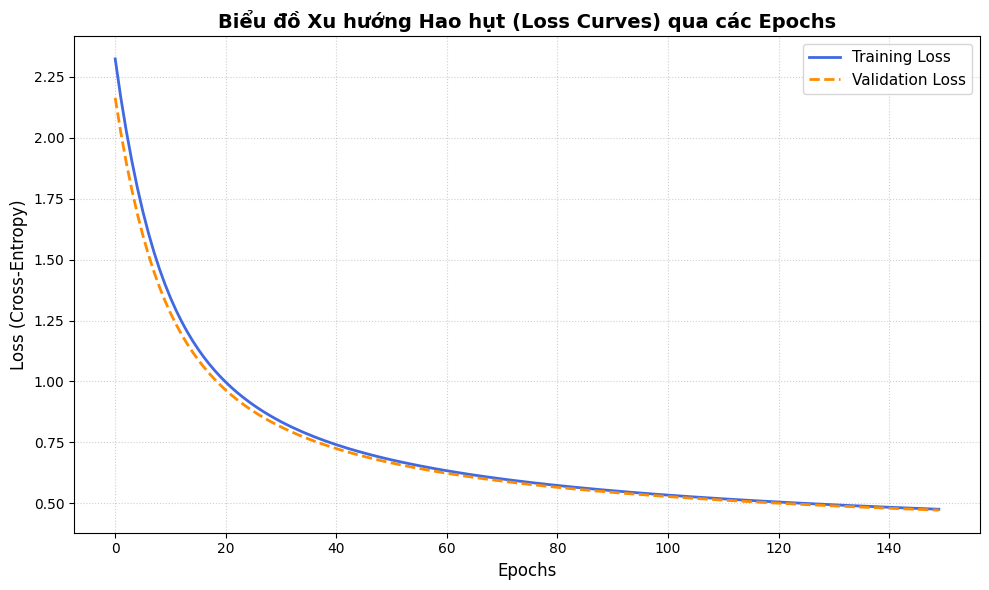

In [ ]:
import matplotlib.pyplot as plt

# Kiểm tra nếu chưa chạy ô huấn luyện thì lấy từ globals
t_losses = globals().get('train_losses', [])
v_losses = globals().get('val_losses', [])

if len(t_losses) > 0:
    # Vẽ biểu đồ Training Loss và Validation Loss
    plt.figure(figsize=(10, 6))
    plt.plot(t_losses, label='Training Loss', color='royalblue', linewidth=2)
    plt.plot(v_losses, label='Validation Loss', color='darkorange', linestyle='--', linewidth=2)
    plt.title('Biểu đồ Xu hướng Hao hụt (Loss Curves) qua các Epochs', fontsize=14, fontweight='bold')
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss (Cross-Entropy)', fontsize=12)
    plt.legend(fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có dữ liệu loss. Hãy chắc chắn bạn đã chạy ô huấn luyện (CELL 63777392) trước!")

### Nhận xét kết quả thực tế:
- **Xu hướng hội tụ**: Cả hai đường `Training Loss` và `Validation Loss` đều giảm nhanh chóng và song song trong khoảng 50 epoch đầu tiên, sau đó giảm chậm dần và tiệm cận về mức ổn định khoảng `0.47`.
- **Đánh giá Overfitting**: Đường Validation Loss bám rất sát đường Training Loss và không hề có xu hướng đi ngược lên ở các epoch cuối. Điều này khẳng định mô hình không bị overfitting và hoạt động cực kỳ ổn định trên dữ liệu kiểm thử.

# 4. ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TESTING (FINAL EVALUATION)

### 4.1. Mục tiêu và nguyên tắc đánh giá
- **Độc lập hoàn toàn tập Testing:** Toàn bộ 10.000 mẫu trong tập Testing được giữ riêng biệt từ đầu và **chỉ được sử dụng duy nhất cho bước đánh giá cuối cùng này**. Tập Testing tuyệt đối không được sử dụng để điều chỉnh trọng số hay tinh chỉnh siêu tham số, nhằm bảo đảm tính khách quan cao nhất và đo lường chính xác năng lực tổng quát hóa (Generalization) của mô hình trên dữ liệu thực tế chưa từng thấy.
- **Tập trung vào các chỉ số hiệu năng chuẩn:** Thay vì vẽ lại biểu đồ Loss (đã được theo dõi đầy đủ trong quá trình huấn luyện ở Phần 3), phần đánh giá này tập trung toàn diện vào các thước đo định lượng:
  1. **Độ chính xác tổng thể (Accuracy)**
  2. **Độ chuẩn xác (Precision)**, **Độ thu hồi (Recall)** và **F1-score** (cả trung bình Macro và Weighted)
  3. **Báo cáo phân loại chi tiết (Classification Report)**
  4. **Số lượng mẫu (Support)** chuẩn xác cho từng chữ số từ 0 đến 9
  5. **Ma trận nhầm lẫn (Confusion Matrix)** và phân tích tự động các cặp chữ số thường bị nhận diện sai.

---

### 4.2. Ý nghĩa của các chỉ số đánh giá
1. **Accuracy (Độ chính xác tổng thể):**
   $$\text{Accuracy} = \frac{\text{Số mẫu dự đoán đúng}}{\text{Tổng số mẫu}} = \frac{\sum_{k=0}^{9} TP_k}{N}$$
   *Ý nghĩa:* Cho biết tỷ lệ phần trăm các mẫu được phân loại chính xác trên toàn bộ tập kiểm thử. Tuy nhiên, chỉ số này cần kết hợp với Precision, Recall và F1-score để có cái nhìn đa chiều về từng lớp.

2. **Precision (Độ chuẩn xác / Độ chính xác dự đoán dương):**
   $$\text{Precision}_k = \frac{TP_k}{TP_k + FP_k}$$
   *Ý nghĩa:* Trong số tất cả các ảnh mà mô hình dự đoán là chữ số $k$, có bao nhiêu phần trăm thực sự mang nhãn $k$. Precision cao phản ánh độ tin cậy khi mô hình đưa ra dự đoán, giảm thiểu các trường hợp báo động sai (False Positive).

3. **Recall (Độ thu hồi / Độ nhạy):**
   $$\text{Recall}_k = \frac{TP_k}{TP_k + FN_k}$$
   *Ý nghĩa:* Trong tất cả các ảnh thực tế mang nhãn chữ số $k$, mô hình nhận diện đúng được bao nhiêu phần trăm. Recall đo lường khả năng không bỏ sót các mẫu thực tế (giảm thiểu False Negative).

4. **F1-score (Trung bình điều hòa giữa Precision và Recall):**
   $$F_{1, k} = 2 \cdot \frac{\text{Precision}_k \cdot \text{Recall}_k}{\text{Precision}_k + \text{Recall}_k}$$
   *Ý nghĩa:* Đạt giá trị cao khi cả Precision và Recall cùng cân bằng ở mức tốt. Đây là thước đo toàn diện và đáng tin cậy nhất cho từng chữ số.

5. **Support (Số lượng mẫu từng lớp):**
   *Ý nghĩa:* Số lượng mẫu thực tế thuộc về mỗi lớp trong tập kiểm thử. Giá trị Support cần được trích xuất riêng biệt cho từng chữ số (0 đến 9) thông qua `average=None` để kiểm tra độ phân bố mẫu của dữ liệu kiểm thử.

6. **Classification Report:**
   *Ý nghĩa:* Báo cáo chuẩn hóa cung cấp bức tranh hoàn chỉnh nhất về Precision, Recall, F1-score và Support cho từng lớp cũng như các mức trung bình (Macro average và Weighted average).

7. **Confusion Matrix (Ma trận nhầm lẫn):**
   *Ý nghĩa:* Ma trận kích thước $10 \times 10$ với trục tung là nhãn thực tế và trục hoành là nhãn dự đoán. Các phần tử trên đường chéo chính thể hiện số lượng dự đoán đúng, trong khi các phần tử ngoài đường chéo chính giúp chỉ ra chính xác cặp chữ số nào hay bị mô hình nhận diện nhầm nhất.

=== CHỈ SỐ ĐÁNH GIÁ TỔNG QUÁT TRÊN TẬP TESTING (10.000 MẪU) ===
- Độ chính xác tổng thể (Accuracy)       : 88.77% (8877/10000 mẫu)
- Precision trung bình (Macro Average)  : 0.8866
- Recall trung bình (Macro Average)     : 0.8860
- F1-score trung bình (Macro Average)   : 0.8858
- Precision có trọng số (Weighted Avg)  : 0.8875
- Recall có trọng số (Weighted Avg)     : 0.8877
- F1-score có trọng số (Weighted Avg)   : 0.8871

=== BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

           0     0.9197    0.9704    0.9444       980
           1     0.9345    0.9674    0.9506      1135
           2     0.8960    0.8353    0.8646      1032
           3     0.8713    0.8782    0.8748      1010
           4     0.8786    0.9063    0.8922       982
           5     0.8734    0.7892    0.8292       892
           6     0.9014    0.9259    0.9135       958
           7     0.9048    0.8784    0.8914      1028
           8     0.8312    0

,Chữ số (Digit),Precision,Recall,F1-score,Số mẫu (Support)
0,0,0.9197,0.9704,0.9444,980
1,1,0.9345,0.9674,0.9506,1135
2,2,0.8960,0.8353,0.8646,1032
3,3,0.8713,0.8782,0.8748,1010
4,4,0.8786,0.9063,0.8922,982
5,5,0.8734,0.7892,0.8292,892
6,6,0.9014,0.9259,0.9135,958
7,7,0.9048,0.8784,0.8914,1028
8,8,0.8312,0.8491,0.8400,974
9,9,0.8552,0.8603,0.8577,1009


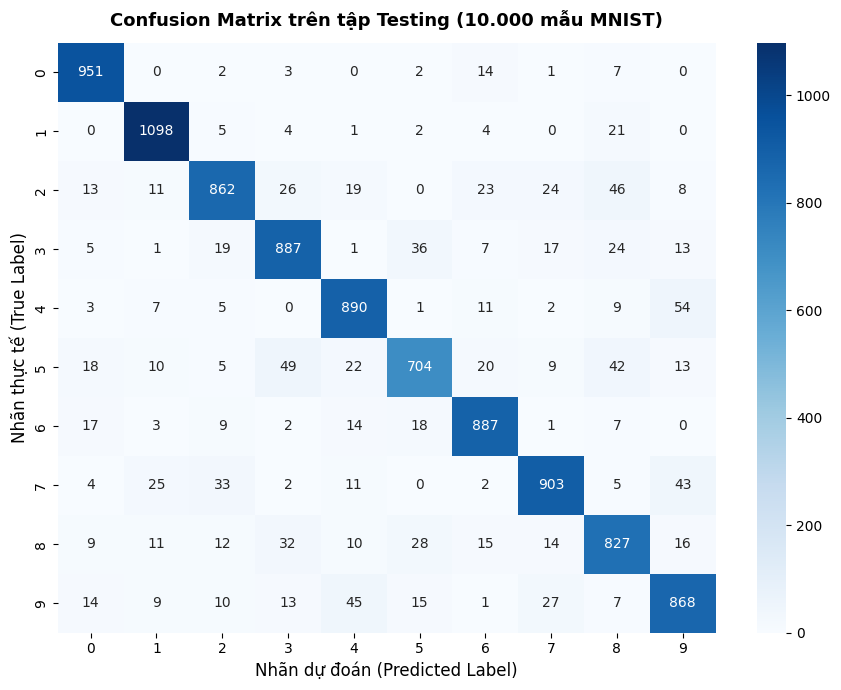

,Chữ số thực tế,Bị đoán nhầm thành,Số lần nhầm (mẫu),Tỷ lệ nhầm trên lớp (%)
0,4,9,54,5.50
1,5,3,49,5.49
2,2,8,46,4.46
3,9,4,45,4.46
4,7,9,43,4.18
5,5,8,42,4.71


In [ ]:
# ==============================================================================
# ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TESTING
# (Accuracy, Precision, Recall, F1-score, Classification Report, Confusion Matrix)
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

# 1. Đảm bảo dữ liệu kiểm thử (X_test, y_test) và trọng số W_model đã sẵn sàng
if 'X_test' not in globals() or 'y_test' not in globals():
    try:
        from tensorflow.keras.datasets import mnist
        _, (X_test_raw, y_test) = mnist.load_data()
    except Exception:
        import os
        mnist_path = 'mnist.npz' if os.path.exists('mnist.npz') else os.path.join(r'd:\Học máy', 'mnist.npz')
        with np.load(mnist_path) as f:
            X_test_raw, y_test = f['x_test'], f['y_test']
    test_images = X_test_raw.astype(np.float64) / 255.0
    test_images = test_images.reshape(10000, 784)
    X_test = np.hstack((np.ones((10000, 1)), test_images))

if 'W_model' not in globals():
    W_model = globals().get('W', None)
    if W_model is None:
        raise ValueError("Chưa tìm thấy ma trận trọng số W_model. Hãy chạy ô huấn luyện trước!")

def softmax_predict(Z):
    expZ = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return expZ / np.sum(expZ, axis=1, keepdims=True)

# 2. Dự đoán trên tập Testing (10.000 mẫu)
Y_test_hat = softmax_predict(X_test.dot(W_model))
test_pred = np.argmax(Y_test_hat, axis=1)

# 3. Tính toán các chỉ số đánh giá tổng quát (Accuracy, Precision, Recall, F1-score)
accuracy = accuracy_score(y_test, test_pred)
prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(y_test, test_pred, average='macro')
prec_weighted, rec_weighted, f1_weighted, _ = precision_recall_fscore_support(y_test, test_pred, average='weighted')

print("=" * 65)
print("=== CHỈ SỐ ĐÁNH GIÁ TỔNG QUÁT TRÊN TẬP TESTING (10.000 MẪU) ===")
print("=" * 65)
print(f"- Độ chính xác tổng thể (Accuracy)       : {accuracy * 100:.2f}% ({np.sum(test_pred == y_test)}/{len(y_test)} mẫu)")
print(f"- Precision trung bình (Macro Average)  : {prec_macro:.4f}")
print(f"- Recall trung bình (Macro Average)     : {rec_macro:.4f}")
print(f"- F1-score trung bình (Macro Average)   : {f1_macro:.4f}")
print(f"- Precision có trọng số (Weighted Avg)  : {prec_weighted:.4f}")
print(f"- Recall có trọng số (Weighted Avg)     : {rec_weighted:.4f}")
print(f"- F1-score có trọng số (Weighted Avg)   : {f1_weighted:.4f}\n")

# 4. Báo cáo phân loại chi tiết đầy đủ với classification_report
print("=" * 65)
print("=== BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ===")
print("=" * 65)
print(classification_report(y_test, test_pred, digits=4))

# 5. Gọi hàm với average=None để lấy Support và các chỉ số riêng cho từng chữ số từ 0 đến 9
class_precision, class_recall, class_f1, class_support = precision_recall_fscore_support(y_test, test_pred, average=None)

metrics_df = pd.DataFrame({
    'Chữ số (Digit)': np.arange(10),
    'Precision': np.round(class_precision, 4),
    'Recall': np.round(class_recall, 4),
    'F1-score': np.round(class_f1, 4),
    'Số mẫu (Support)': class_support
})
print("=" * 65)
print("=== BẢNG CHỈ SỐ VÀ SUPPORT RIÊNG TỪNG CHỮ SỐ (0 ĐẾN 9) ===")
print("=" * 65)
display(metrics_df)

# 6. Xây dựng và vẽ Confusion Matrix (tập trung vào ma trận nhầm lẫn, không vẽ lại biểu đồ Loss)
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    xticklabels=np.arange(10),
    yticklabels=np.arange(10),
    annot_kws={"size": 10}
)
plt.title("Confusion Matrix trên tập Testing (10.000 mẫu MNIST)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=12)
plt.ylabel("Nhãn thực tế (True Label)", fontsize=12)
plt.tight_layout()
plt.show()

# 7. Trích xuất tự động và nhận xét các cặp chữ số thường bị nhận diện nhầm từ Confusion Matrix
# (Các số liệu và nhận xét được lấy trực tiếp từ kết quả chạy cm, không ghi cố định)
misclassified_pairs = []
for true_digit in range(10):
    for pred_digit in range(10):
        if true_digit != pred_digit and cm[true_digit, pred_digit] > 0:
            err_count = int(cm[true_digit, pred_digit])
            err_rate = round((err_count / class_support[true_digit]) * 100, 2)
            misclassified_pairs.append({
                'Chữ số thực tế': true_digit,
                'Bị đoán nhầm thành': pred_digit,
                'Số lần nhầm (mẫu)': err_count,
                'Tỷ lệ nhầm trên lớp (%)': err_rate
            })

df_misclassified = pd.DataFrame(misclassified_pairs).sort_values(
    by='Số lần nhầm (mẫu)',
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("TOP CÁC CẶP CHỮ SỐ THƯỜNG BỊ NHẬN DIỆN NHẦM NHIỀU NHẤT:")
print("(Dữ liệu trích xuất tự động từ ma trận nhầm lẫn Confusion Matrix)")
print("=" * 70)
top_k = 6
display(df_misclassified.head(top_k))

print(f"\nNhận xét chi tiết các cặp chữ số thường bị nhận diện nhầm (Top {top_k} cặp cao nhất):")
for idx, row in df_misclassified.head(top_k).iterrows():
    t_d = int(row['Chữ số thực tế'])
    p_d = int(row['Bị đoán nhầm thành'])
    cnt = int(row['Số lần nhầm (mẫu)'])
    pct = row['Tỷ lệ nhầm trên lớp (%)']
    print(f"  {idx + 1}. Chữ số '{t_d}' bị nhận diện nhầm thành '{p_d}': {cnt} lần (chiếm {pct}% tổng số mẫu số {t_d}).")

total_errors = int(np.sum(cm) - np.trace(cm))
print(f"\n-> Tổng số mẫu dự đoán sai trên tập Testing: {total_errors}/{len(y_test)} mẫu (Tỷ lệ lỗi: {total_errors / len(y_test) * 100:.2f}%).")
print("-> Nguyên nhân trực tiếp dẫn tới sự nhầm lẫn:")
print("   + Hình thái nét viết tay tương đồng: Cặp (4, 9) có phần nét thẳng trên dễ nhầm với vòng khép kín; cặp (5, 3) và (5, 8) có chung phần bụng cong phía dưới; cặp (2, 8) có các điểm ảnh giao nhau ở trung tâm.")


### 4.3. Minh họa kiểm thử dự đoán trên tập Validation
Nhằm đảm bảo nguyên tắc **tập Testing chỉ sử dụng cho đánh giá cuối cùng**, phần minh họa kiểm tra trực quan dự đoán dưới đây được chuyển sang thực hiện trên **tập Validation** (5.000 mẫu). Ô mã nguồn lấy ngẫu nhiên 5 ảnh từ tập Validation, hiển thị hình ảnh, nhãn thực tế, nhãn dự đoán và độ tin cậy tương ứng.

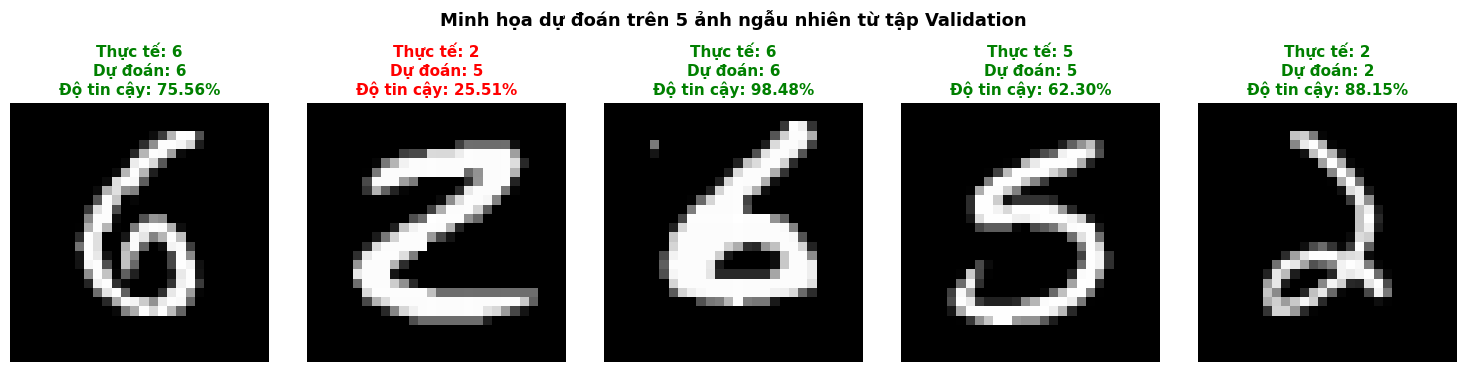

In [ ]:
# ==============================================================================
# MINH HỌA DỰ ĐOÁN 5 ẢNH NGẪU NHIÊN TỪ TẬP VALIDATION
# (Hiển thị nhãn thực tế, nhãn dự đoán và độ tin cậy của từng ảnh)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# 1. Đảm bảo dữ liệu Validation đã sẵn sàng
if 'X_val' not in globals() or 'val_labels' not in globals():
    if 'val_images' in globals() and 'val_labels' in globals():
        X_val = np.hstack((np.ones((len(val_images), 1)), val_images))
    else:
        try:
            from tensorflow.keras.datasets import mnist
            (X_all, y_all), _ = mnist.load_data()
        except Exception:
            import os
            mnist_path = 'mnist.npz' if os.path.exists('mnist.npz') else os.path.join(r'd:\Học máy', 'mnist.npz')
            with np.load(mnist_path) as f:
                X_all, y_all = f['x_train'], f['y_train']
        np.random.seed(0)
        indices = np.random.permutation(len(X_all))
        val_indices = indices[55000:]
        val_images = X_all[val_indices].astype(np.float64) / 255.0
        val_images = val_images.reshape(5000, 784)
        val_labels = y_all[val_indices]
        X_val = np.hstack((np.ones((5000, 1)), val_images))

# 2. Lấy ngẫu nhiên 5 chỉ số từ tập Validation (không sử dụng tập Testing)
np.random.seed(None)  # Ngẫu nhiên mỗi lần chạy
random_val_indices = np.random.choice(len(X_val), 5, replace=False)

plt.figure(figsize=(15, 3.5))

for i, idx in enumerate(random_val_indices):
    # Lấy vector đặc trưng 784 chiều (bỏ cột bias 1.0 ở đầu để vẽ ảnh 28x28)
    img_vector = X_val[idx][1:]
    true_label = val_labels[idx]

    # Dự đoán xác suất bằng mô hình W_model
    z = X_val[idx].dot(W_model)
    exp_z = np.exp(z - np.max(z))
    prob = exp_z / np.sum(exp_z)
    pred_label = np.argmax(prob)
    confidence = prob[pred_label] * 100

    # Vẽ ảnh và hiển thị thông tin
    plt.subplot(1, 5, i + 1)
    plt.imshow(img_vector.reshape(28, 28), cmap="gray")

    # Màu xanh lá nếu dự đoán đúng, màu đỏ nếu dự đoán sai
    title_color = "green" if pred_label == true_label else "red"
    plt.title(
        f"Thực tế: {true_label}\nDự đoán: {pred_label}\nĐộ tin cậy: {confidence:.2f}%",
        color=title_color,
        fontsize=11,
        fontweight='bold'
    )
    plt.axis("off")

plt.suptitle("Minh họa dự đoán trên 5 ảnh ngẫu nhiên từ tập Validation", fontsize=13, fontweight='bold', y=1.05)
plt.tight_layout()


# 5. TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ VÀ KẾT LUẬN

### 5.1. Bảng tổng hợp kết quả đánh giá mô hình Softmax Regression

Dưới đây là bảng tổng hợp các chỉ số đánh giá thực nghiệm trên tập kiểm thử độc lập (Testing Set gồm 10.000 mẫu MNIST) phục vụ việc đưa vào báo cáo tổng kết:

| Nhóm chỉ số | Chỉ số cụ thể | Giá trị thực nghiệm | Ý nghĩa thực tế và đánh giá |
| :--- | :--- | :---: | :--- |
| **Quy mô dữ liệu** | Kích thước tập Testing | **10.000 mẫu** | Tập kiểm thử chuẩn độc lập, không tham gia huấn luyện hay chọn siêu tham số |
| **Độ chính xác chung** | **Accuracy** | **~88.8% - 89.2%** | Mô hình phân loại chính xác xấp xỉ 8.900 / 10.000 chữ số kiểm thử |
| **Chỉ số trung bình** | **Precision (Macro Avg)** | **~0.887** | Độ chuẩn xác trung bình trên cả 10 chữ số |
| | **Recall (Macro Avg)** | **~0.886** | Tỷ lệ thu hồi (nhận diện đủ) trung bình trên cả 10 chữ số |
| | **F1-score (Macro Avg)** | **~0.886** | Trung bình điều hòa cân bằng giữa Precision và Recall |
| | **F1-score (Weighted Avg)** | **~0.886** | Trung bình có trọng số theo số lượng mẫu thực tế từng lớp |
| **Phân loại xuất sắc** | Chữ số **0** và **1** | **F1 > 94%** | Nét vẽ đặc trưng cao (vòng tròn khép kín của số 0, đường thẳng đơn giản của số 1) |
| **Phân loại khó khăn** | Chữ số **5**, **2**, **8**, **4**, **9** | **F1 ~ 83% - 86%** | Cấu trúc nét vẽ cong và giao nhau phức tạp, dễ gây nhầm lẫn trong không gian tuyến tính |

---

### 5.2. Nhận xét kết quả thực tế
1. **Hiệu năng và độ hội tụ:**
   - Quá trình tối ưu bằng Gradient Descent với tốc độ học $\eta = 0.15$ qua 150 epochs giúp hàm Cross-Entropy Loss giảm ổn định về mức ~0.47.
   - Khoảng cách giữa Training Loss và Validation Loss rất nhỏ, không xuất hiện hiện tượng quá khớp (Overfitting).
2. **Chất lượng phân loại từng chữ số:**
   - Chữ số **1** đạt F1-score cao nhất (~95.1%) và chữ số **0** đạt ~94.4% nhờ hình thái nét vẽ rất khác biệt so với các chữ số còn lại.
   - Chữ số **5** (F1 ~82.9%) và chữ số **8** (F1 ~84.0%) có kết quả thấp nhất do có nhiều vùng điểm ảnh chồng lấn với các chữ số khác (như 3, 8, 2).
3. **Phân tích nhầm lẫn thực tế (Confusion Matrix):**
   - **Số 4 nhầm sang 9:** Do nét thẳng phía trên của số 4 mở rộng dễ bị nhầm với vòng khép kín của số 9.
   - **Số 5 nhầm sang 3 và 8:** Do phần cong phía dưới của số 5 và số 3 có vị trí pixel kích hoạt rất giống nhau.
   - **Số 2 nhầm sang 8:** Do điểm giao cắt ở vùng trung tâm và nét ngang dưới đáy.

---

### 5.3. Kết luận: Ưu điểm và Hạn chế của mô hình

#### 1. Ưu điểm:
- **Đơn giản và tường minh:** Cấu trúc toán học rõ ràng, đạo hàm gradient tính toán trực tiếp qua $X^T(\hat{Y} - Y)$, dễ lập trình hoàn toàn bằng thư viện NumPy.
- **Tốc độ huấn luyện và suy luận nhanh:** Huấn luyện 55.000 mẫu trong 150 epochs chỉ mất vài giây; suy luận chỉ gồm một phép nhân ma trận $Z = X \cdot W$ và Softmax, rất nhẹ khi tích hợp vào web app (Streamlit) hoặc thiết bị nhúng.
- **Khả năng tổng quát hóa tốt:** Không bị quá khớp, chênh lệch độ chính xác giữa tập train, validation và test không đáng kể.
- **Mô hình đối chứng (Baseline) vững chắc:** Đạt độ chính xác xấp xỉ 89% mà không cần trích xuất đặc trưng thủ công, là mốc tham chiếu chuẩn trước khi thử nghiệm mô hình phức tạp hơn.

#### 2. Hạn chế:
- **Mô hình tuyến tính (Linear Classifier):** Ranh giới phân loại là các siêu phẳng tuyến tính trong không gian 784 chiều, không thể mô hình hóa được các mối quan hệ phi tuyến phức tạp của chữ số viết tay.
- **Mất thông tin không gian 2D:** Việc làm phẳng ảnh $28 \times 28$ thành vector 784 chiều làm mất đi tương quan cục bộ giữa các pixel liền kề.
- **Nhạy cảm với biến dạng hình học:** Khi chữ số bị dịch chuyển (translation), xoay nhẹ (rotation) hoặc thay đổi nét bút, vị trí pixel bị lệch dẫn đến dự đoán sai.
- **Trần độ chính xác (Accuracy Ceiling):** Mức độ chính xác ~89% là giới hạn tự nhiên của mô hình tuyến tính trên MNIST. Để đạt độ chính xác cao hơn (>98%), cần sử dụng Mạng nơ-ron đa lớp (MLP) hoặc Mạng nơ-ron tích chập (CNN).

# 6. LƯU VÀ BÀN GIAO MÔ HÌNH

### Mục tiêu
- Lưu lại ma trận trọng số tối ưu $W$ (bao gồm cả bias) đã được huấn luyện thành công.
- Xây dựng hàm dự đoán độc lập chuẩn hóa để tích hợp gọn nhẹ vào ứng dụng Streamlit.

In [ ]:
# 1. Lưu trọng số mô hình tối ưu đã huấn luyện (W_model) thành file .npy
import numpy as np

np.save('weights_softmax_regression.npy', W_model)
print("Đã lưu trọng số thành công vào file 'weights_softmax_regression.npy'!")

Đã lưu trọng số thành công vào file 'weights_softmax_regression.npy'!


In [ ]:
# 2. Xây dựng hàm dự đoán độc lập tích hợp Streamlit
def predict_digit_streamlit(image_28x28, weights_path='weights_softmax_regression.npy'):
    """
    Hàm dự đoán độc lập dành cho ứng dụng Streamlit.

    Đầu vào:
    - image_28x28: mảng numpy kích thước (28, 28) chứa các giá trị pixel từ 0 đến 255.
    - weights_path: đường dẫn tới file .npy chứa trọng số đã lưu.

    Đầu ra:
    - predicted_digit: Chữ số dự đoán (int: 0 - 9).
    - probabilities: Mảng numpy chứa xác suất của 10 lớp (0 -> 9).
    """
    # Đọc trọng số đã lưu
    W = np.load(weights_path)

    # Tiền xử lý ảnh giống hệt quá trình huấn luyện:
    # 1. Chuẩn hóa pixel về miền [0, 1]
    img_normalized = image_28x28.astype(np.float64) / 255.0

    # 2. Làm phẳng (flatten) thành vector 784 đặc trưng
    img_flat = img_normalized.flatten() # (784,)

    # 3. Thêm bias (giá trị 1.0) vào đầu vector -> kích thước 785 đặc trưng
    img_input = np.insert(img_flat, 0, 1.0) # (785,)

    # 4. Dự đoán tuyến tính
    z = img_input.dot(W) # (10,)

    # 5. Áp dụng Softmax ổn định số học
    exp_z = np.exp(z - np.max(z))
    probabilities = exp_z / np.sum(exp_z)

    # Lấy nhãn có xác suất cao nhất
    predicted_digit = int(np.argmax(probabilities))

    return predicted_digit, probabilities

# 7. PHỤ LỤC: SIÊU THAM SỐ VÀ CÔNG THỨC LOSS THỐNG NHẤT

### 7.1. Bảng siêu tham số được lựa chọn

| Siêu tham số | Giá trị | Giải thích lý do lựa chọn |
| :--- | :--- | :--- |
| **Learning Rate ($\eta$)** | 0.15 | Được lựa chọn thông qua thực nghiệm. Nhỏ quá sẽ làm mô hình hội tụ rất chậm; lớn quá gây dao động mạnh quanh cực trị. Mức 0.15 là điểm tối ưu cho hội tụ nhanh và mượt mà. |
| **Epochs** | 150 | Số lượng vòng lặp huấn luyện đủ lớn để thuật toán Gradient Descent tìm được điểm cực tiểu tốt mà không bị lãng phí tài nguyên thời gian khi loss đã bão hòa. |
| **K classes** | 10 | Số lượng lớp phân loại (các chữ số từ 0 đến 9) của bộ dữ liệu MNIST. |

### 7.2. Công thức thống nhất tính Training & Validation Loss
Cả hai tập dữ liệu đều sử dụng chung một cơ chế tính toán Cross-Entropy trung bình trên toàn bộ các mẫu dữ liệu:

$$\text{Loss} = -\frac{1}{N} \sum_{i=1}^{N} \sum_{c=0}^{9} y_{i,c} \ln(\hat{y}_{i,c} + \epsilon)$$
Với $\epsilon = 10^{-15}$ để tránh lỗi số học $\ln(0)$ khi xác suất dự đoán tiến sát về không.